# 03 — Resist Chemistry Chain (Dill ABC → PEB → Development)

This notebook demonstrates the full resist chemistry simulation:
1. **Dill ABC exposure** — photon absorption → acid generation
2. **PEB (Post-Exposure Bake)** — acid diffusion + deprotection reaction
3. **Development** — Mack model dissolution
4. **Stochastic effects** — photon shot noise → LER/LWR

This is the `resist_model="full_chem"` pipeline in euvsimulator.

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from euvsimulator.pipeline import SimulationConfig, run_simulation
from euvsimulator.resist.exposure import dose_to_acid
from euvsimulator.resist.peb import reaction_diffusion_analytical
from euvsimulator.resist.develop import MackModel, threshold_development
from euvsimulator.resist.stochastic import ler_lwr_estimate, rms_scaling_check

## 1. Dill ABC Exposure Model

Photon absorption → acid generation:

$$A(x) = 1 - e^{-C \cdot D(x)}$$

- $A$: relative acid concentration (fraction of the PAG converted)
- $C$: photo-rate constant [cm²/mJ]; it already contains the PAG quantum efficiency, there is no
  separate prefactor (a former $Q$ factor double-counted it and was removed on 2026-09-04, see
  `docs/physics.md`)
- $D(x)$: local dose [mJ/cm²]

The standalone demonstration below uses C = 0.05 cm²/mJ for a clearly visible signal; the chain's
default is 0.0152 cm²/mJ (LBNL base titration).

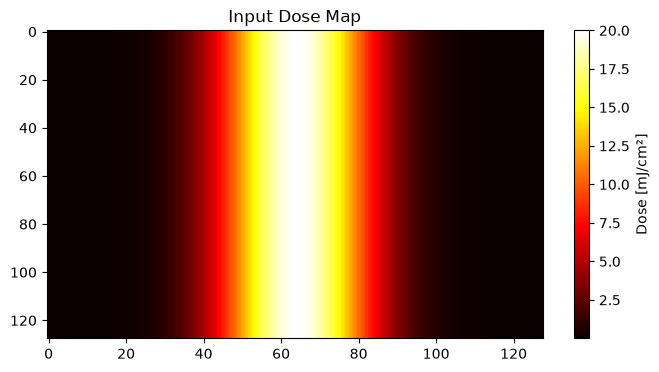

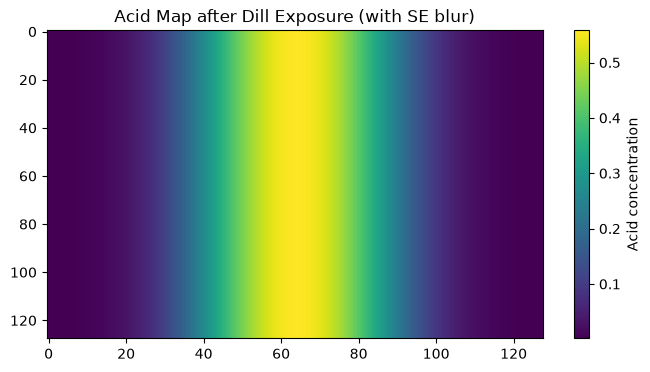

In [2]:
# Generate a test dose map (Gaussian line)
grid = 128
dx = 0.5  # nm
x = np.arange(grid) * dx
dose_map = torch.tensor(
    20.0 * np.exp(-((x - grid*dx/2) / 10.0)**2),  # 20 mJ/cm² peak
    dtype=torch.float32
).unsqueeze(0).expand(grid, grid)

plt.figure(figsize=(8, 4))
plt.imshow(dose_map.numpy(), cmap="hot", aspect="auto")
plt.colorbar(label="Dose [mJ/cm²]")
plt.title("Input Dose Map")
plt.show()

# Dill exposure
acid = dose_to_acid(
    dose_map,
    C=0.05,      # cm²/mJ
    sigma_blur=5.0,  # SE blur
    dx=dx
)

plt.figure(figsize=(8, 4))
plt.imshow(acid.numpy(), cmap="viridis", aspect="auto")
plt.colorbar(label="Acid concentration")
plt.title("Acid Map after Dill Exposure (with SE blur)")
plt.show()

## 2. PEB — Reaction-Diffusion

Two coupled processes during bake:
1. **Diffusion**: acid spreads with σ_diff
2. **Deprotection**: inhibitor → deprotected (rate k)

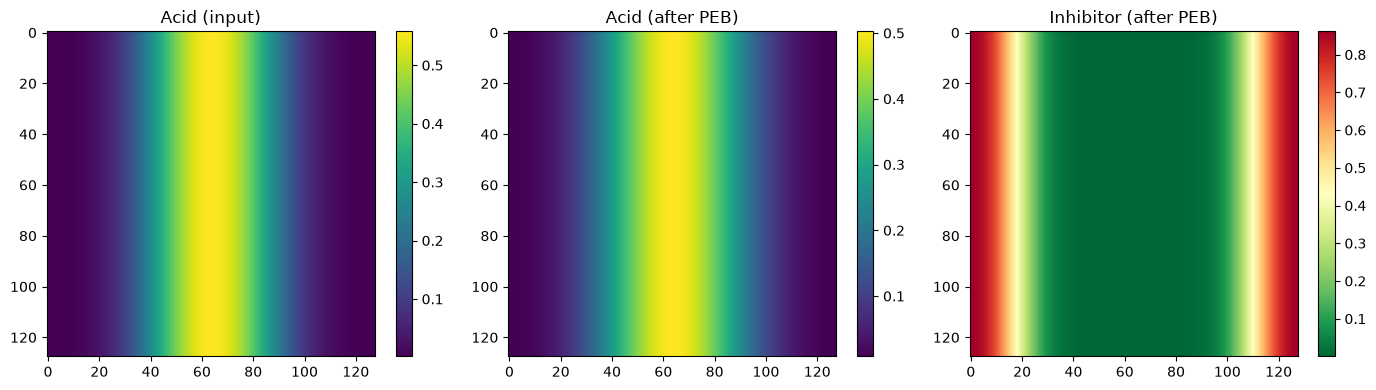

Deprotection at center: 1.000


In [3]:
inhib_in = torch.ones_like(acid)  # start fully inhibited

acid_out, inhib_out = reaction_diffusion_analytical(
    acid,
    inhib_in,
    k=0.3,        # s⁻¹
    t_bake=60.0,  # s
    sigma_diff=5.0,  # nm
    dx=dx
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

im0 = axes[0].imshow(acid.numpy(), cmap="viridis", aspect="auto")
axes[0].set_title("Acid (input)")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(acid_out.numpy(), cmap="viridis", aspect="auto")
axes[1].set_title("Acid (after PEB)")
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(inhib_out.numpy(), cmap="RdYlGn_r", aspect="auto")
axes[2].set_title("Inhibitor (after PEB)")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

print(f"Deprotection at center: {1 - inhib_out[grid//2, grid//2]:.3f}")

## 3. Development (Mack Model)

The chain dissolves the resist at the enhanced Mack rate (`resist.develop.MackModel`):

$$R(M) = R_{max} \frac{(a+1)(1-M)^n}{a + (1-M)^n} + R_{min}, \qquad a = \frac{n+1}{n-1}(1-M_{th})^n$$

- $M$: remaining inhibitor (protection) fraction, so the rate is high where $M$ is low
- $n$: dissolution selectivity; $M_{th}$: inflection point of $R(M)$ (not the half-rate point)

In `run_simulation(resist_model="full_chem")` this rate drives an eikonal development front
through the film (Section 5). The cell below plots the rate for the chain's default resist and
then, as a quick picture of the latent image, cuts the inhibitor map of Section 2 at 0.5 with
`threshold_development` (a binary cut, not the chain's development: 1 = developed, 0 = resist
remaining).

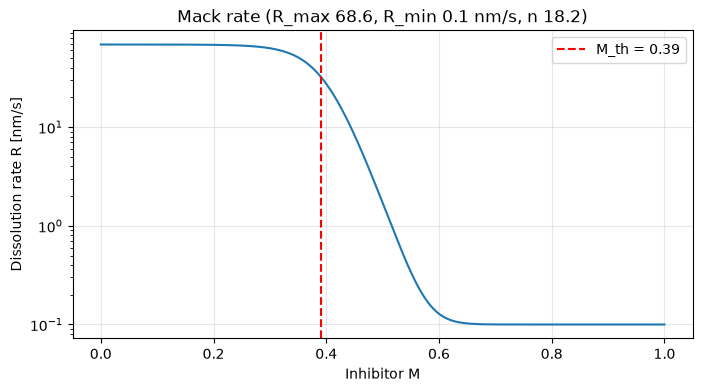

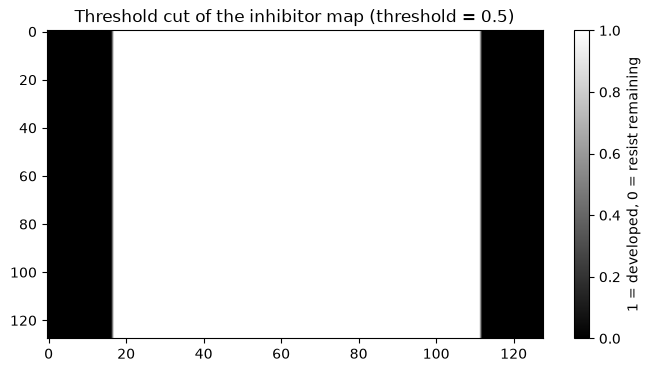

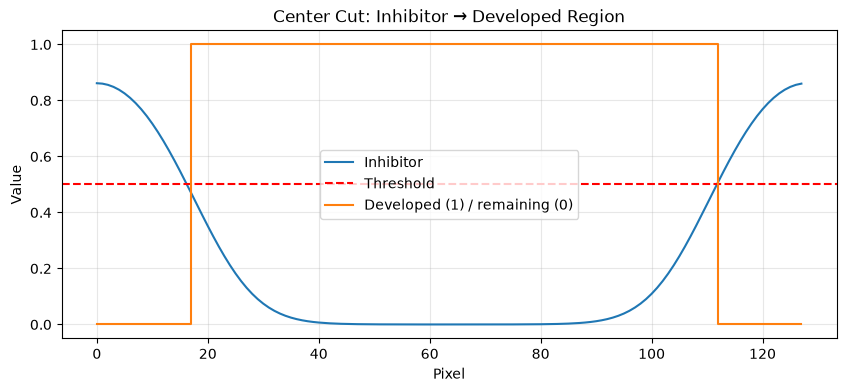

In [4]:
# Mack dissolution rate with the chain's default parameters (Yamamoto et al. 2011)
ref = SimulationConfig()
mack = MackModel(R_max=ref.mack_R_max, R_min=ref.mack_R_min, n=ref.mack_n, M_th=ref.mack_M_th)
M = torch.linspace(0.0, 1.0, 201, dtype=torch.float64)

plt.figure(figsize=(8, 4))
plt.semilogy(M.numpy(), mack.rate(M).numpy())
plt.axvline(mack.M_th, color='r', linestyle='--', label=f"M_th = {mack.M_th}")
plt.xlabel("Inhibitor M")
plt.ylabel("Dissolution rate R [nm/s]")
plt.title(f"Mack rate (R_max {mack.R_max}, R_min {mack.R_min} nm/s, n {mack.n})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Binary threshold cut of the inhibitor map, for visualization only
dev = threshold_development(inhib_out, threshold=0.5)

plt.figure(figsize=(8, 4))
plt.imshow(dev.numpy(), cmap="gray", aspect="auto")
plt.colorbar(label="1 = developed, 0 = resist remaining")
plt.title("Threshold cut of the inhibitor map (threshold = 0.5)")
plt.show()

# Show center cut
plt.figure(figsize=(10, 4))
plt.plot(inhib_out[grid//2, :].numpy(), label="Inhibitor")
plt.axhline(0.5, color='r', linestyle='--', label="Threshold")
plt.plot(dev[grid//2, :].numpy(), label="Developed (1) / remaining (0)", drawstyle='steps-post')
plt.xlabel("Pixel")
plt.ylabel("Value")
plt.title("Center Cut: Inhibitor → Developed Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 4. Stochastic Effects — Photon Shot Noise

At EUV doses, photon statistics matter:
- 20 mJ/cm² delivers 13.6 photons per nm² (photon energy 91.84 eV); a 50 nm film with the default
  absorption (4.44 µm⁻¹) absorbs about 20 % of them, ≈ 2.7 per nm²
- Poisson noise → LER/LWR

The photon-statistics law itself is demonstrated in notebook 05 (Sections 2–7). Here the
stochastic chain runs end to end in Section 5 below.

## 5. Full Pipeline Integration (Stochastic)

In [5]:
cfg = SimulationConfig(
    period_nm=64.0,
    line_width_nm=32.0,
    # Dose is the WAFER dose in a clear area (Mack 1997 convention). The default resist prints
    # the 32 nm line at about 1.3 mJ/cm² (dose-to-size at grid 128; 4 mJ/cm² would shrink it
    # to ~9 nm). The PEB blur is the chain's own default (σ ≈ 7.9 nm).
    dose_mj_cm2=1.3,
    resist_model="full_chem",
    enable_stochastic=True,
    stochastic_n_realisations=5,
    stochastic_seed=42,
    grid=128,
)

result = run_simulation(cfg)

print(f"CD: {result.cd_nm:.2f} nm")
print(f"NILS: {result.nils_value:.3f}")
print(f"LER: {result.ler_nm:.3f} nm")
print(f"LWR: {result.lwr_nm:.3f} nm")

CD: 31.82 nm
NILS: 4.622
LER: 1.981 nm
LWR: 3.242 nm


## Summary

| Step | Physics | euvsimulator Module |
|------|---------|-------------|
| Exposure | Dill ABC | `resist.exposure.dose_to_acid` |
| PEB | Reaction-diffusion | `resist.peb.reaction_diffusion_analytical` |
| Development | Mack rate, eikonal front | `resist.develop.MackModel` (Section 3 also shows a `threshold_development` cut) |
| Stochastics | Shot noise → LER/LWR | `pipeline.run_simulation(enable_stochastic=True)` |

**Key insight:** in a pure shot-noise model (notebook 05, Sections 2–7) LER follows 1/√D by
construction. The full chain does not: near the dose-to-size the Mack
development makes the edge response strongly non-linear, and the dissolution-cell noise adds
a floor that does not scale with dose (see notebook 05 and `docs/physics.md`).